In [1]:
import yfinance as yf

df = yf.download("^NSEI", start="2010-01-01", end="2026-10-24", progress=False)
print(df.shape)
print(df.head())
print(df.tail())
print(df.isna().sum())

e:\Github\Projects\sip-vs-lumpsum\.venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)


(4128, 5)
Price             Close         High          Low         Open Volume
Ticker            ^NSEI        ^NSEI        ^NSEI        ^NSEI  ^NSEI
Date                                                                 
2010-01-04  5232.200195  5238.450195  5167.100098  5200.899902      0
2010-01-05  5277.899902  5288.350098  5242.399902  5277.149902      0
2010-01-06  5281.799805  5310.850098  5260.049805  5278.149902      0
2010-01-07  5263.100098  5302.549805  5244.750000  5281.799805      0
2010-01-08  5244.750000  5276.750000  5234.700195  5264.250000      0
Price              Close          High           Low          Open  Volume
Ticker             ^NSEI         ^NSEI         ^NSEI         ^NSEI   ^NSEI
Date                                                                      
2026-10-16  23146.150391  23149.849609  22913.800781  23065.099609  391600
2026-10-19  22888.949219  23175.250000  22845.000000  23150.849609  285800
2026-10-21  22811.349609  23120.900391  22649.900391  2

e:\Github\Projects\sip-vs-lumpsum\.venv\Lib\site-packages\yfinance\utils.py:514: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(
e:\Github\Projects\sip-vs-lumpsum\.venv\Lib\site-packages\yfinance\utils.py:518: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.rename(columns={
e:\Github\Projects\sip-vs-lumpsum\.venv\Lib\site-packages\yfinance\multi.py:220: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.rename(columns=ctx.isins, inplace=True)
e:\Github\Projects\sip-vs

In [2]:
import warnings
warnings.filterwarnings("ignore")

In [3]:
df.columns = df.columns.get_level_values(0)
print(df.columns.tolist())

['Close', 'High', 'Low', 'Open', 'Volume']


In [4]:
close = df["Close"]
monthly = close.groupby(close.index.to_period("M")).agg(["first", "mean", "last"])
print(monthly.shape)
print(monthly.head())
print(monthly.tail())

(202, 3)
               first         mean         last
Date                                          
2010-01  5232.200195  5156.223684  4882.049805
2010-02  4899.700195  4843.905273  4922.299805
2010-03  5017.000000  5178.147624  5249.100098
2010-04  5290.500000  5294.755054  5278.000000
2010-05  5222.750000  5052.971401  5086.299805
                first          mean          last
Date                                             
2026-06  23382.599609  23683.145182  23865.750000
2026-07  24005.849609  24133.632473  24383.599609
2026-08  24774.300781  24361.273996  24080.400391
2026-09  24055.800781  23377.468936  22620.449219
2026-10  22421.949219  22663.236458  22600.000000


In [5]:
from pathlib import Path

Path("../data/raw").mkdir(parents=True, exist_ok=True)
df[["Close"]].to_csv("../data/raw/nifty50_close.csv")

In [6]:
import pandas as pd

check = pd.read_csv("../data/raw/nifty50_close.csv", index_col="Date", parse_dates=True)
print(check.shape)
print(check.index.dtype)
print(check.tail(2))

(4128, 1)
datetime64[us]
                   Close
Date                    
2026-10-22  22687.650391
2026-10-23  22600.000000


In [7]:
s = check["Close"]

print("sorted:", s.index.is_monotonic_increasing)
print("duplicate dates:", s.index.duplicated().sum())
print("prices <= 0:", (s <= 0).sum())

gaps = s.index.to_series().diff().dt.days
print("longest gap (days):", gaps.max(), "ending", gaps.idxmax().date())

ret = s.pct_change().dropna()
print(ret.nsmallest(3))
print(ret.nlargest(3))

sorted: True
duplicate dates: 0
prices <= 0: 0
longest gap (days): 6.0 ending 2014-10-07
Date
2020-03-23   -0.129805
2020-03-12   -0.083019
2020-03-16   -0.076121
Name: Close, dtype: float64
Date
2020-04-07    0.087632
2020-03-25    0.066247
2020-03-20    0.058329
Name: Close, dtype: float64


In [8]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

from src.data import monthly_buy_prices

In [9]:
""" commented out 
def monthly_buy_prices(close, sip_day=1):
    rows = []
    for period in close.index.to_period("M").unique():
        month = close[close.index.to_period("M") == period]
        eligible = month[month.index.day >= sip_day]
        if len(eligible) == 0:
            continue
        rows.append({"month": period,
                     "buy_date": eligible.index[0],
                     "price": eligible.iloc[0]})
    return pd.DataFrame(rows).set_index("month")
"""

' commented out \ndef monthly_buy_prices(close, sip_day=1):\n    rows = []\n    for period in close.index.to_period("M").unique():\n        month = close[close.index.to_period("M") == period]\n        eligible = month[month.index.day >= sip_day]\n        if len(eligible) == 0:\n            continue\n        rows.append({"month": period,\n                     "buy_date": eligible.index[0],\n                     "price": eligible.iloc[0]})\n    return pd.DataFrame(rows).set_index("month")\n'

In [10]:
b13 = monthly_buy_prices(close, sip_day=13)
print(b13.head(6))
print(b13[b13["buy_date"].dt.day != 13].head())

          buy_date        price
month                          
2010-01 2010-01-13  5233.950195
2010-02 2010-02-15  4801.950195
2010-03 2010-03-15  5128.899902
2010-04 2010-04-13  5322.950195
2010-05 2010-05-13  5178.899902
2010-06 2010-06-14  5197.700195
          buy_date        price
month                          
2010-02 2010-02-15  4801.950195
2010-03 2010-03-15  5128.899902
2010-06 2010-06-14  5197.700195
2010-11 2010-11-15  6121.600098
2011-02 2011-02-14  5456.000000


In [11]:
Path("../data/processed").mkdir(parents=True, exist_ok=True)
monthly_buy_prices(close, sip_day=1).to_csv("../data/processed/buy_prices_day1.csv")

In [12]:
import warnings
warnings.filterwarnings("ignore")

import yfinance as yf

g = yf.download("GOLDBEES.NS", start="2010-01-01", end="2026-10-24", progress=False)
g.columns = g.columns.get_level_values(0)
print(g.shape)
print(g.head(3))
print(g.tail(3))
print(g.isna().sum())

(4146, 5)
Price         Close       High        Low  Open   Volume
Date                                                    
2010-01-04  16.5499  16.559000  16.381100   0.0  3967700
2010-01-05  16.6800  16.709900  16.600000   0.0  5367100
2010-01-06  16.6000  16.759899  16.581301   0.0  5224100
Price            Close        High         Low        Open    Volume
Date                                                                
2026-10-21  118.129997  118.800003  117.949997  118.660004  27637611
2026-10-22  117.349998  117.629997  116.699997  117.190002  20537960
2026-10-23  115.900002  116.139999  115.050003  115.660004  28346630
Price
Close     0
High      0
Low       0
Open      0
Volume    0
dtype: int64


In [13]:
from pathlib import Path
import pandas as pd

gs = g["Close"]

print("sorted:", gs.index.is_monotonic_increasing)
print("duplicate dates:", gs.index.duplicated().sum())
print("prices <= 0:", (gs <= 0).sum())

gaps = gs.index.to_series().diff().dt.days
print("longest gap (days):", gaps.max(), "ending", gaps.idxmax().date())

ret = gs.pct_change().dropna()
print(ret.nsmallest(3))
print(ret.nlargest(3))

Path("../data/raw").mkdir(parents=True, exist_ok=True)
g[["Close"]].to_csv("../data/raw/gold_close.csv")

nifty = pd.read_csv("../data/raw/nifty50_close.csv", index_col="Date", parse_dates=True)
print("only in gold:", len(gs.index.difference(nifty.index)),
      "| only in nifty:", len(nifty.index.difference(gs.index)))

sorted: True
duplicate dates: 0
prices <= 0: 0
longest gap (days): 6.0 ending 2014-10-07
Date
2019-12-19   -0.990014
2026-01-30   -0.105166
2026-02-02   -0.094951
Name: Close, dtype: float64
Date
2019-12-23    99.000008
2026-01-29     0.078854
2026-01-21     0.072382
Name: Close, dtype: float64
only in gold: 19 | only in nifty: 1


In [14]:
print(gs["2019-12-13":"2019-12-27"])
print(gs.index.difference(nifty.index)[:5])

Date
2019-12-13    33.220501
2019-12-16    33.443001
2019-12-17    33.502998
2019-12-18    33.596001
2019-12-19     0.335500
2019-12-20     0.336500
2019-12-23    33.650002
2019-12-24    33.750000
2019-12-26    34.000000
2019-12-27    34.150002
Name: Close, dtype: float64
DatetimeIndex(['2011-05-31', '2011-07-14', '2011-11-24', '2011-12-26',
               '2012-01-02'],
              dtype='datetime64[s]', name='Date', freq=None)


In [15]:
gold_clean = gs.copy()
bad = gold_clean.index.isin(pd.to_datetime(["2019-12-19", "2019-12-20"]))
gold_clean[bad] = gold_clean[bad] * 100

print(gold_clean["2019-12-17":"2019-12-24"])

ret2 = gold_clean.pct_change().dropna()
print(ret2.nsmallest(3))
print(ret2.nlargest(3))

Path("../data/processed").mkdir(parents=True, exist_ok=True)
gold_clean.to_csv("../data/processed/gold_close_clean.csv")
nifty["Close"].to_csv("../data/processed/nifty50_close_clean.csv")

Date
2019-12-17    33.502998
2019-12-18    33.596001
2019-12-19    33.550000
2019-12-20    33.649999
2019-12-23    33.650002
2019-12-24    33.750000
Name: Close, dtype: float64
Date
2026-01-30   -0.105166
2026-02-02   -0.094951
2026-03-23   -0.085412
Name: Close, dtype: float64
Date
2026-01-29    0.078854
2026-01-21    0.072382
2026-05-13    0.057219
Name: Close, dtype: float64


In [16]:
import pandas as pd

nifty = pd.read_csv("../data/processed/nifty50_close_clean.csv", index_col=0, parse_dates=True).iloc[:, 0]
gold  = pd.read_csv("../data/processed/gold_close_clean.csv",  index_col=0, parse_dates=True).iloc[:, 0]

gold_only = gold.index.difference(nifty.index)

check = pd.DataFrame({
    "weekday": gold_only.day_name(),
    "gold_close": gold.loc[gold_only].values,
    "prev_gold_close": gold.shift(1).loc[gold_only].values,
}, index=gold_only)
check["same_as_prev"] = check["gold_close"] == check["prev_gold_close"]

print(check.to_string())
print(check["same_as_prev"].sum(), "of", len(check), "are identical to the previous close")

              weekday  gold_close  prev_gold_close  same_as_prev
Date                                                            
2011-05-31    Tuesday   21.904499        21.814501         False
2011-07-14   Thursday   22.276501        22.018999         False
2011-11-24   Thursday   27.488501        27.392500         False
2011-12-26     Monday   26.481001        26.514999         False
2012-01-02     Monday   26.192499        26.102501         False
2012-05-21     Monday   27.787319        27.846430         False
2012-08-28    Tuesday   29.604900        29.561871         False
2013-01-01    Tuesday   29.042959        29.039860         False
2014-01-01  Wednesday   27.243000        27.174999         False
2014-02-17     Monday   28.527000        28.101500         False
2015-01-01   Thursday   24.563499        24.641500         False
2015-04-15  Wednesday   24.188000        24.360500         False
2016-01-01     Friday   22.802000        22.792500         False
2016-08-12     Friday   2

In [17]:
import sys
sys.path.append("..")
from src.data import monthly_buy_prices

n = monthly_buy_prices(nifty)
g = monthly_buy_prices(gold)

months = n.index.intersection(g.index)
diff = pd.DataFrame({
    "nifty_buy": n.loc[months, "buy_date"],
    "gold_buy": g.loc[months, "buy_date"],
})
diff = diff[diff["nifty_buy"] != diff["gold_buy"]]

print(len(n), "nifty months,", len(g), "gold months,", len(diff), "months with different buy dates")
print(diff)

202 nifty months, 202 gold months, 7 months with different buy dates
         nifty_buy   gold_buy
month                        
2012-01 2012-01-03 2012-01-02
2013-01 2013-01-02 2013-01-01
2014-01 2014-01-02 2014-01-01
2015-01 2015-01-02 2015-01-01
2016-01 2016-01-04 2016-01-01
2018-01 2018-01-02 2018-01-01
2019-01 2019-01-02 2019-01-01


In [18]:
import sys
sys.path.append("..")
from src.investing import lump_sum, sip

toy_prices = [100, 80, 120]
final_price = 130
monthly = 5000

ls = lump_sum(buy_price=toy_prices[0], final_price=final_price, amount=monthly * len(toy_prices))
sp = sip(buy_prices=toy_prices, final_price=final_price, monthly_amount=monthly)

print("lump sum:", ls)
print("sip     :", sp)

lump sum: {'units': 150.0, 'invested': 15000, 'final_value': 19500.0, 'gain': 4500.0}
sip     : {'units': 154.16666666666666, 'invested': 15000, 'final_value': 20041.666666666664, 'gain': 5041.666666666664}


In [19]:
from src.data import monthly_buy_prices

n = monthly_buy_prices(nifty)
prices = n["price"].tolist()

final_price = nifty.iloc[-1]
monthly = 5000
total = monthly * len(prices)          # same total money for both

ls = lump_sum(buy_price=prices[0], final_price=final_price, amount=total)
sp = sip(buy_prices=prices, final_price=final_price, monthly_amount=monthly)

for name, r in [("lump sum", ls), ("sip", sp)]:
    print(f"{name:9} invested {r['invested']:>10,.0f}  final {r['final_value']:>12,.0f}  "
          f"gain {r['gain']:>12,.0f}  gain/invested {r['gain']/r['invested']:.2f}x")

lump sum  invested  1,010,000  final    4,362,601  gain    3,352,601  gain/invested 3.32x
sip       invested  1,010,000  final    2,418,251  gain    1,408,251  gain/invested 1.39x


In [20]:
from src.metrics import cagr, xirr

buy_dates = pd.to_datetime(n["buy_date"]).tolist()
final_date = nifty.index[-1]

# SIP again, this time with dates, so it returns cash_flows
sp = sip(buy_prices=prices, final_price=nifty.iloc[-1], monthly_amount=monthly,
         buy_dates=buy_dates, final_date=final_date)

years = (final_date - buy_dates[0]).days / 365    # same days/365 rule as xirr

ls_cagr = cagr(start_value=total, end_value=ls["final_value"], years=years)
ls_xirr = xirr([(buy_dates[0], -total), (final_date, ls["final_value"])])
sip_xirr = xirr(sp["cash_flows"])

print(f"years              {years:.3f}")
print(f"lump sum CAGR      {ls_cagr:.4%}")
print(f"lump sum XIRR      {ls_xirr:.4%}   (should equal the CAGR)")
print(f"SIP XIRR           {sip_xirr:.4%}")

years              16.811
lump sum CAGR      9.0933%
lump sum XIRR      9.0933%   (should equal the CAGR)
SIP XIRR           9.6215%


In [21]:
from src.compare import run_asset

for name, series in [("nifty", nifty), ("gold", gold)]:
    r = run_asset(series)
    print(f"{name:6} months {r['months']}  years {r['years']:.3f}  invested {r['invested']:,.0f}")
    print(f"       lump sum final {r['ls_final']:>12,.0f}  CAGR {r['ls_cagr']:.4%}")
    print(f"       SIP      final {r['sip_final']:>12,.0f}  XIRR {r['sip_xirr']:.4%}")

nifty  months 202  years 16.811  invested 1,010,000
       lump sum final    4,362,601  CAGR 9.0933%
       SIP      final    2,418,251  XIRR 9.6215%
gold   months 202  years 16.811  invested 1,010,000
       lump sum final    7,073,094  CAGR 12.2747%
       SIP      final    3,656,940  XIRR 13.8546%


In [22]:
from src.investing import fd

rate = 0.079
years = (nifty.index[-1] - pd.to_datetime(monthly_buy_prices(nifty)["buy_date"].iloc[0])).days / 365
total = 5000 * 202

fd_ls = fd(amount=total, annual_rate=rate, years=years)

# recurring version: each 5,000 is its own FD from its buy date to the final date
m = monthly_buy_prices(nifty)
buy_dates = pd.to_datetime(m["buy_date"]).tolist()
final_date = nifty.index[-1]

fd_final = sum(fd(5000, rate, (final_date - d).days / 365)["final_value"] for d in buy_dates)
fd_flows = [(d, -5000) for d in buy_dates] + [(final_date, fd_final)]

print(f"FD lump sum  final {fd_ls['final_value']:>12,.0f}  CAGR {cagr(total, fd_ls['final_value'], years):.4%}")
print(f"FD monthly   final {fd_final:>12,.0f}  XIRR {xirr(fd_flows):.4%}")

FD lump sum  final    3,626,131  CAGR 7.9000%
FD monthly   final    2,052,488  XIRR 7.9000%


In [23]:
from src.metrics import max_drawdown

rows = []
for name, series in [("Nifty", nifty), ("Gold", gold)]:
    r = run_asset(series)
    dd = series / series.cummax() - 1
    rows.append({
        "asset": name,
        "lump_final": r["ls_final"],
        "lump_cagr": r["ls_cagr"],
        "sip_final": r["sip_final"],
        "sip_xirr": r["sip_xirr"],
        "max_drawdown": max_drawdown(series),
        "trough_date": dd.idxmin().date(),
    })

rows.append({
    "asset": "FD 7.9%",
    "lump_final": fd_ls["final_value"],
    "lump_cagr": cagr(total, fd_ls["final_value"], years),
    "sip_final": fd_final,
    "sip_xirr": xirr(fd_flows),
    "max_drawdown": float("nan"),     # a fixed-rate deposit has no price to fall
    "trough_date": None,
})

summary = pd.DataFrame(rows).set_index("asset")
print(summary.round(4).to_string())

           lump_final  lump_cagr     sip_final  sip_xirr  max_drawdown trough_date
asset                                                                             
Nifty    4.362601e+06     0.0909  2.418251e+06    0.0962       -0.3844  2020-03-23
Gold     7.073094e+06     0.1227  3.656940e+06    0.1385       -0.2740  2015-08-06
FD 7.9%  3.626131e+06     0.0790  2.052488e+06    0.0790           NaN        None


In [24]:
for f in [1.0, 0.9, 0.8]:
    g2 = gold.copy()
    g2.iloc[-1] = gold.iloc[-1] * f      # change only the last close
    r = run_asset(g2)
    print(f"final price x{f:.1f}  lump CAGR {r['ls_cagr']:.4%}  SIP XIRR {r['sip_xirr']:.4%}")

final price x1.0  lump CAGR 12.2747%  SIP XIRR 13.8546%
final price x0.9  lump CAGR 11.5732%  SIP XIRR 12.7884%
final price x0.8  lump CAGR 10.7943%  SIP XIRR 11.5873%


end values: Nifty 432  Gold 700  FD 359


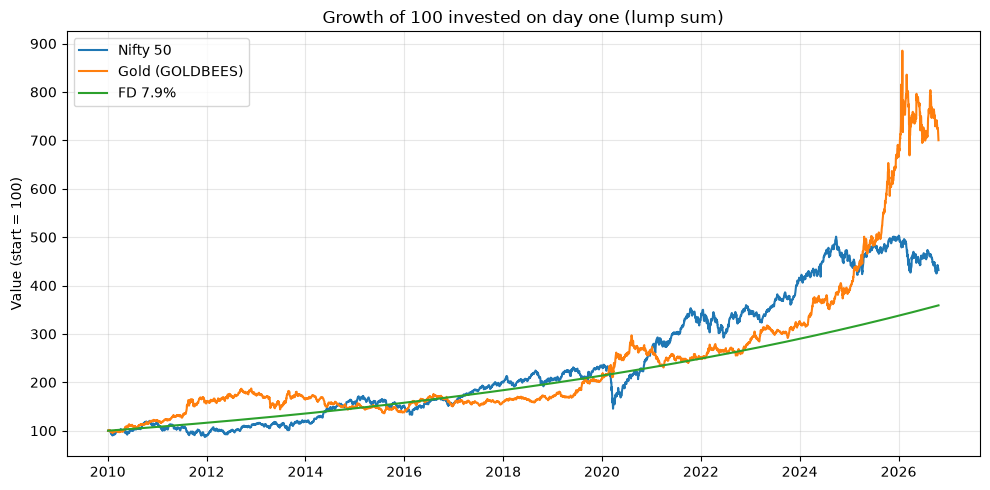

In [25]:
import os
import matplotlib.pyplot as plt

start = max(pd.to_datetime(monthly_buy_prices(s)["buy_date"].iloc[0]) for s in (nifty, gold))
n = nifty.loc[start:]
g = gold.loc[start:]

n_idx = n / n.iloc[0] * 100
g_idx = g / g.iloc[0] * 100
fd_idx = 100 * 1.079 ** ((n.index - start).days / 365)

print(f"end values: Nifty {n_idx.iloc[-1]:.0f}  Gold {g_idx.iloc[-1]:.0f}  FD {fd_idx[-1]:.0f}")

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(n_idx.index, n_idx, label="Nifty 50")
ax.plot(g_idx.index, g_idx, label="Gold (GOLDBEES)")
ax.plot(n.index, fd_idx, label="FD 7.9%")
ax.set_title("Growth of 100 invested on day one (lump sum)")
ax.set_ylabel("Value (start = 100)")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()

os.makedirs("../charts", exist_ok=True)
fig.savefig("../charts/growth_lump_sum.png", dpi=150)
plt.show()

max drawdown: Nifty -38.44% on 2020-03-23, Gold -27.40% on 2015-08-06


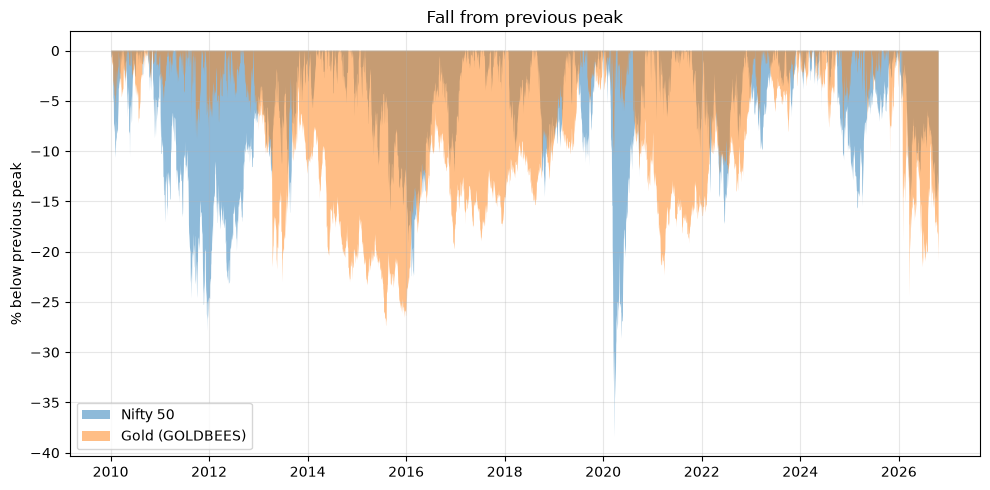

In [26]:
import os
import pandas as pd
import matplotlib.pyplot as plt

nifty = pd.read_csv("../data/processed/nifty50_close_clean.csv", index_col=0, parse_dates=True).iloc[:, 0]
gold  = pd.read_csv("../data/processed/gold_close_clean.csv",  index_col=0, parse_dates=True).iloc[:, 0]

dd_n = nifty / nifty.cummax() - 1
dd_g = gold / gold.cummax() - 1

print(f"max drawdown: Nifty {dd_n.min():.2%} on {dd_n.idxmin().date()}, "
      f"Gold {dd_g.min():.2%} on {dd_g.idxmin().date()}")

fig, ax = plt.subplots(figsize=(10, 5))
ax.fill_between(dd_n.index, dd_n * 100, 0, alpha=0.5, label="Nifty 50")
ax.fill_between(dd_g.index, dd_g * 100, 0, alpha=0.5, label="Gold (GOLDBEES)")
ax.set_title("Fall from previous peak")
ax.set_ylabel("% below previous peak")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()

os.makedirs("../charts", exist_ok=True)
fig.savefig("../charts/drawdown.png", dpi=150)
plt.show()

lump sum: [np.float64(9.09), np.float64(12.27), 7.9]
SIP     : [9.62, 13.85, 7.9]


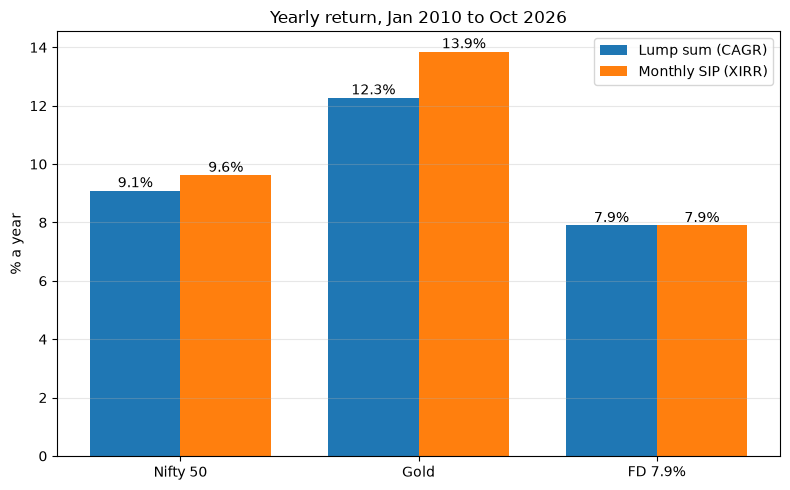

In [27]:
import os, sys
sys.path.append("..")
import pandas as pd
import matplotlib.pyplot as plt
from src.compare import run_asset

nifty = pd.read_csv("../data/processed/nifty50_close_clean.csv", index_col=0, parse_dates=True).iloc[:, 0]
gold  = pd.read_csv("../data/processed/gold_close_clean.csv",  index_col=0, parse_dates=True).iloc[:, 0]

res = {"Nifty 50": run_asset(nifty), "Gold": run_asset(gold)}

labels = ["Nifty 50", "Gold", "FD 7.9%"]
lump_vals = [res["Nifty 50"]["ls_cagr"] * 100, res["Gold"]["ls_cagr"] * 100, 7.9]
sip_vals  = [res["Nifty 50"]["sip_xirr"] * 100, res["Gold"]["sip_xirr"] * 100, 7.9]

print("lump sum:", [round(v, 2) for v in lump_vals])
print("SIP     :", [round(v, 2) for v in sip_vals])

x = range(len(labels))
w = 0.38
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar([i - w / 2 for i in x], lump_vals, w, label="Lump sum (CAGR)")
ax.bar([i + w / 2 for i in x], sip_vals, w, label="Monthly SIP (XIRR)")
ax.set_xticks(list(x))
ax.set_xticklabels(labels)
ax.set_ylabel("% a year")
ax.set_title("Yearly return, Jan 2010 to Oct 2026")
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f%%")
ax.grid(axis="y", alpha=0.3)
ax.legend()
fig.tight_layout()

os.makedirs("../charts", exist_ok=True)
fig.savefig("../charts/yearly_returns.png", dpi=150)
plt.show()